# Hackathon – Dataset C (COVID vaccine) · Notebook 08 of 09
## Final model selection and the five ranked submission files

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


In [2]:
from IPython.display import display

In [3]:
BEST_PREP = load_json('best_prep.json')
TUNED = build_tuned_models(BEST_PREP, load_json('tuned_params.json'))
cv_folds = load_csv('cv_folds.csv')                          # notebook 06
hold_table = load_csv('holdout_table.csv', index_col=0)      # notebook 07
robust = load_csv('robustness.csv', index_col=0)             # notebook 07
cand = [m for m in MODEL_ORDER if not m.startswith('Baseline')]
print('loaded results for', len(cand), 'candidate models')

loaded results for 7 candidate models


## 8. Final model selection and submission
### 8.1 Leaderboard and the selection rule
We combine both validation sources, weighted by how much data each one uses: **0.8 × repeated-CV cost (development set) + 0.2 × hold-out cost**.

**Selection rule (decided before looking at the test set):**
1. Slots 1–4: the four best *personal-threshold* candidates by the combined estimate (personal thresholds were the best strategy for every model in CV, on hold-out, and in 4/5 scenarios).
2. Slot 5: the best *single-threshold* candidate under the flat-risk scenario C – a hedge in case the marking uses one average hospitalisation probability. It is ranked last because under our own (main) metric it is the most expensive of the five.

In [4]:
lead_rows = []
for m in cand:
    for s in ['single thr', 'personal thr']:
        cv_s = cv_folds.loc[cv_folds['model'] == m, f'$/resident [{s}]']
        lead_rows.append({'candidate': f'{m} | {s}', 'model': m, 'strategy': s,
                          'CV mean $': cv_s.mean(), 'CV std $': cv_s.std(),
                          'hold-out $': hold_table.loc[m, f'$/resident [{s}]'],
                          'flat-scenario hold-out $': robust.loc[f'{m} | {s}', 'C: flat town average'],
                          'robustness mean rank': robust.loc[f'{m} | {s}', 'mean rank']})
leaderboard = pd.DataFrame(lead_rows)
leaderboard['combined $'] = 0.8 * leaderboard['CV mean $'] + 0.2 * leaderboard['hold-out $']
leaderboard = leaderboard.sort_values('combined $').reset_index(drop=True)

personal = leaderboard[leaderboard['strategy'] == 'personal thr'].head(4)
hedge = leaderboard[leaderboard['strategy'] == 'single thr'].sort_values('flat-scenario hold-out $').head(1)
FINAL = pd.concat([personal, hedge]).reset_index(drop=True)
FINAL.index = FINAL.index + 1
FINAL.index.name = 'submission rank'
display(leaderboard.round(1))
FINAL.to_csv(ART_DIR / 'final_selection.csv')
FINAL[['candidate', 'CV mean $', 'CV std $', 'hold-out $', 'combined $', 'flat-scenario hold-out $', 'robustness mean rank']].round(1)

,candidate,model,strategy,CV mean $,CV std $,hold-out $,flat-scenario hold-out $,robustness mean rank,combined $
0,XGBoost | personal thr,XGBoost,personal thr,3043.1,65.6,3207.5,3378.0,4.0,3076.0
1,LightGBM | personal thr,LightGBM,personal thr,3044.5,61.4,3205.3,3370.7,3.4,3076.6
2,Ensemble (LR+XGB+LGBM+Cat) | personal thr,Ensemble (LR+XGB+LGBM+Cat),personal thr,3041.5,64.8,3222.2,3391.7,6.4,3077.7
3,Logistic Regression | personal thr,Logistic Regression,personal thr,3050.7,69.2,3201.8,3383.7,3.0,3080.9
4,CatBoost | personal thr,CatBoost,personal thr,3049.7,59.4,3230.0,3397.4,7.8,3085.8
5,Random Forest + isotonic | personal thr,Random Forest + isotonic,personal thr,3053.1,52.7,3226.2,3395.4,7.4,3087.7
6,Random Forest | personal thr,Random Forest,personal thr,3052.6,60.7,3242.5,3424.4,11.0,3090.5
7,Ensemble (LR+XGB+LGBM+Cat) | single thr,Ensemble (LR+XGB+LGBM+Cat),single thr,3112.3,61.3,3233.7,3326.0,5.6,3136.5
8,XGBoost | single thr,XGBoost,single thr,3113.9,65.5,3234.7,3324.1,6.2,3138.0
9,LightGBM | single thr,LightGBM,single thr,3113.8,68.9,3246.0,3339.9,9.0,3140.2


,candidate,CV mean $,CV std $,hold-out $,combined $,flat-scenario hold-out $,robustness mean rank
submission rank,,,,,,,
1,XGBoost | personal thr,3043.1,65.6,3207.5,3076.0,3378.0,4.0
2,LightGBM | personal thr,3044.5,61.4,3205.3,3076.6,3370.7,3.4
3,Ensemble (LR+XGB+LGBM+Cat) | personal thr,3041.5,64.8,3222.2,3077.7,3391.7,6.4
4,Logistic Regression | personal thr,3050.7,69.2,3201.8,3080.9,3383.7,3.0
5,Logistic Regression | single thr,3116.7,63.9,3245.0,3142.4,3315.5,7.2


### 8.2 Re-train on **all** labelled data and predict the test town
The selected configurations (same hyper-parameters) are re-fitted on all 4 756 training rows – more data gives slightly better models – and
applied to the 4 749 test residents. The file format follows `dataset_C_example_submission.csv` exactly (`respondent_id`, `covid_vaccine` as 0.0/1.0).

In [5]:
def slug(text):
    return ''.join(ch if ch.isalnum() else '_' for ch in text).strip('_').replace('__', '_').lower()

FINAL_MODELS, TEST_PROBS, sub_rows = {}, {}, []
for rank, row in FINAL.iterrows():
    if row['model'] not in FINAL_MODELS:
        FINAL_MODELS[row['model']] = clone(TUNED[row['model']]).fit(X_all, y_all)
        TEST_PROBS[row['model']] = FINAL_MODELS[row['model']].predict_proba(X_test)[:, 1]
    send = decide(TEST_PROBS[row['model']], X_test, row['strategy'])
    sub = pd.DataFrame({ID: test_raw[ID].to_numpy(), TARGET: send.astype(float)})
    path = SUB_DIR / f"{rank}_{slug(row['model'].split(' (')[0])}_{slug(row['strategy'])}.csv"
    sub.to_csv(path, index=False)
    sub_rows.append({'rank': rank, 'file': path.name, 'model': row['model'], 'strategy': row['strategy'],
                     'vaccines posted': int(send.sum()), '% of residents': round(100 * send.mean(), 1)})

# ---- Check every file against the example submission ----
for r in sub_rows:
    f = pd.read_csv(SUB_DIR / r['file'])
    assert list(f.columns) == list(sample_sub.columns), 'wrong columns'
    assert len(f) == len(sample_sub) and (f[ID].to_numpy() == sample_sub[ID].to_numpy()).all(), 'ids/order differ'
    assert set(f[TARGET].unique()) <= {0.0, 1.0}, 'values must be 0.0/1.0'
print('All 5 files match the required format.')
sub_summary = pd.DataFrame(sub_rows).set_index('rank')
sub_summary

All 5 files match the required format.


,file,model,strategy,vaccines posted,% of residents
rank,,,,,
1,1_xgboost_personal_thr.csv,XGBoost,personal thr,1650,34.7
2,2_lightgbm_personal_thr.csv,LightGBM,personal thr,1653,34.8
3,3_ensemble_personal_thr.csv,Ensemble (LR+XGB+LGBM+Cat),personal thr,1638,34.5
4,4_logistic_regression_personal_thr.csv,Logistic Regression,personal thr,1669,35.1
5,5_logistic_regression_single_thr.csv,Logistic Regression,single thr,1808,38.1


,expected total $ for the test town
1: 1_xgboost_personal_thr.csv,"14,933,416"
2: 2_lightgbm_personal_thr.csv,"14,937,932"
3: 3_ensemble_personal_thr.csv,"14,928,564"
4: 4_logistic_regression_personal_thr.csv,"14,957,036"
5: 5_logistic_regression_single_thr.csv,"15,206,472"
(reference) send to nobody,"18,531,103"
(reference) send to everybody,"17,963,975"


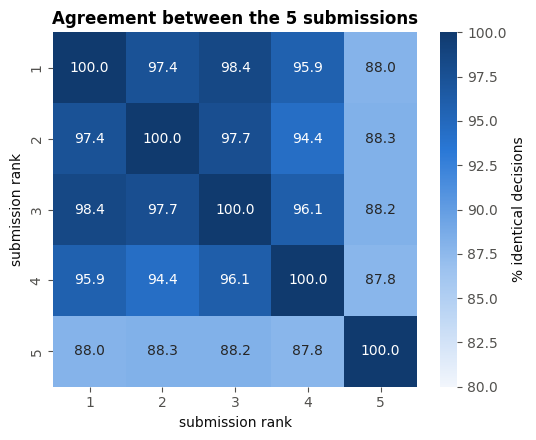

In [6]:
# Expected cost of each submission on the test town. The true labels are unknown, so we use the best model's
# probabilities (ensemble, re-trained on all data) as the expected acceptance: E[cost] = sum over residents.
q_ref = clone(TUNED['Ensemble (LR+XGB+LGBM+Cat)']).fit(X_all, y_all).predict_proba(X_test)[:, 1] \
    if 'Ensemble (LR+XGB+LGBM+Cat)' not in TEST_PROBS else TEST_PROBS['Ensemble (LR+XGB+LGBM+Cat)']
p_test = MAIN.p_unvacc(X_test)

def expected_cost(send, q, p, ve=MAIN.ve):
    send = send.astype(bool)
    vacc = np.where(send, VACCINE_COST, q * VACCINE_COST)                 # posted dose, or cash if willing
    hosp = HOSP_COST * p * np.where(send, 1 - q * ve, 1.0)                 # protected only if sent AND accepted
    return float((vacc + hosp).sum())

exp_rows = {}
for r in sub_rows:
    send = pd.read_csv(SUB_DIR / r['file'])[TARGET].to_numpy()
    exp_rows[f"{r['rank']}: {r['file']}"] = expected_cost(send, q_ref, p_test)
exp_rows['(reference) send to nobody'] = expected_cost(np.zeros(len(X_test)), q_ref, p_test)
exp_rows['(reference) send to everybody'] = expected_cost(np.ones(len(X_test)), q_ref, p_test)
exp = pd.Series(exp_rows, name='expected total $ for the test town')
exp.to_csv(ART_DIR / 'expected_test_costs.csv')
display(exp.map('{:,.0f}'.format).to_frame())

# How similar are the five submissions?
decisions = pd.DataFrame({r['rank']: pd.read_csv(SUB_DIR / r['file'])[TARGET] for r in sub_rows})
agree = pd.DataFrame([[(decisions[a] == decisions[b]).mean() for b in decisions] for a in decisions],
                     index=decisions.columns, columns=decisions.columns)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(agree * 100, annot=True, fmt='.1f', cmap=SEQ_CMAP, vmin=80, vmax=100, ax=ax, cbar_kws={'label': '% identical decisions'})
ax.set_title('Agreement between the 5 submissions'); ax.set_xlabel('submission rank'); ax.set_ylabel('submission rank')
plt.tight_layout(); savefig('08_submission_agreement'); plt.show()

### 8.3 Justification of the order
The text below is generated from the results, so it always matches the numbers above.

In [7]:
# ---- Why each submission is where it is (text generated from the results, so it always matches them) ----
from IPython.display import Markdown, display
personal_lb = leaderboard[leaderboard['strategy'] == 'personal thr']
lines = []
for rank, row in FINAL.iterrows():
    if row['strategy'] == 'personal thr':
        notes = [f"combined estimate \\${row['combined $']:,.1f} per resident "
                 f"(CV \\${row['CV mean $']:,.1f} ± {row['CV std $']:.1f}, hold-out \\${row['hold-out $']:,.1f})"]
        if row['candidate'] == leaderboard.iloc[0]['candidate']:
            notes.append('**best combined estimate**')
        if np.isclose(row['CV mean $'], personal_lb['CV mean $'].min()):
            notes.append('**lowest repeated-CV cost**')
        if np.isclose(row['hold-out $'], personal_lb['hold-out $'].min()):
            notes.append('**lowest hold-out cost**')
        if np.isclose(row['robustness mean rank'], personal_lb['robustness mean rank'].min()):
            notes.append('**most robust across the hospitalisation scenarios**')
    else:
        gap = row['combined $'] - FINAL.iloc[0]['combined $']
        notes = [f"**hedge** – cheapest candidate if the marker gives everybody the same hospitalisation risk "
                 f"(scenario C: \\${row['flat-scenario hold-out $']:,.1f} per resident), but ≈\\${gap:,.0f} per resident more "
                 f"expensive under our main metric, so it is ranked last"]
    lines.append(f"{rank}. **{row['candidate']}** – " + '; '.join(notes))

spread = FINAL.iloc[:4]['combined $'].max() - FINAL.iloc[:4]['combined $'].min()
cv_sd = FINAL.iloc[:4]['CV std $'].mean()
lines.append(f"\n**Critical note.** Submissions 1–4 differ by only ≈\\${spread:.1f} per resident, while the fold-to-fold standard deviation is "
             f"≈\\${cv_sd:.0f}; their order is our best estimate but could swap on the test town. What is robust is that they all clearly beat "
             f"posting to nobody, posting to everybody and a naive 0.5 threshold.")
display(Markdown('\n'.join(lines)))

1. **XGBoost | personal thr** – combined estimate \$3,076.0 per resident (CV \$3,043.1 ± 65.6, hold-out \$3,207.5); **best combined estimate**
2. **LightGBM | personal thr** – combined estimate \$3,076.6 per resident (CV \$3,044.5 ± 61.4, hold-out \$3,205.3)
3. **Ensemble (LR+XGB+LGBM+Cat) | personal thr** – combined estimate \$3,077.7 per resident (CV \$3,041.5 ± 64.8, hold-out \$3,222.2); **lowest repeated-CV cost**
4. **Logistic Regression | personal thr** – combined estimate \$3,080.9 per resident (CV \$3,050.7 ± 69.2, hold-out \$3,201.8); **lowest hold-out cost**; **most robust across the hospitalisation scenarios**
5. **Logistic Regression | single thr** – **hedge** – cheapest candidate if the marker gives everybody the same hospitalisation risk (scenario C: \$3,315.5 per resident), but ≈\$66 per resident more expensive under our main metric, so it is ranked last

**Critical note.** Submissions 1–4 differ by only ≈\$4.9 per resident, while the fold-to-fold standard deviation is ≈\$65; their order is our best estimate but could swap on the test town. What is robust is that they all clearly beat posting to nobody, posting to everybody and a naive 0.5 threshold.

**Next:** notebook 09 explains what the models learned (SHAP, odds ratios, permutation importance) and summarises the project.